## Recomendación: Vecindario

- Filtrado colaborativo de vecindario: **user-user** (entidad-entidad) e **item-item** (proveedor-proveedor)

- Se elige la señal y el número de vecinos en validación (2023 → 2024) y se evalúa en test (2023-2024 → 2025)

### Constantes

- `RANGO_K_VEC`: vecinos que conserva cada entidad (user-user) o cada proveedor (item-item)

- `RANGO_SENAL`: señales implícitas que se comparan

In [1]:
RANGO_K_VEC = [10, 20, 50, 100, 200, 400]
RANGO_SENAL = ["binaria", "n_adj", "log_monto"]

### Utilidades

In [2]:
NOTEBOOK = "b_vecindario"
%run ../funciones.ipynb
%run funciones.ipynb

Note: you may need to restart the kernel to use updated packages.


In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

Particiones y catálogo de `a_preparacion`

In [4]:
cfg = leer_config()
ctx = {(p, s): contexto(p, s) for p in PARTICIONES for s in RANGO_SENAL}
for p in PARTICIONES:
    c = ctx[(p, "binaria")]
    print(f"{p}: matriz {c['forma'][0]:,} × {c['forma'][1]:,} | {c['X'].nnz:,} pares | catálogo {c['catalogo'].sum():,} | "
          f"entidades a evaluar {len(c['entidades']):,}")

val: matriz 2,992 × 86,017 | 51,185 pares | catálogo 5,474 | entidades a evaluar 2,023
test: matriz 2,992 × 86,017 | 96,022 pares | catálogo 9,653 | entidades a evaluar 2,112


---
### **1. User-user**

- Coseno entre las filas de la matriz: dos entidades se parecen si adjudican a los mismos proveedores

- Puntaje(e, p) = Σ similitud(e, v) · señal(v, p) sobre las `k` vecinas v de e

In [5]:
grilla_u = []
for s in RANGO_SENAL:
    c = ctx[("val", s)]
    for k in RANGO_K_VEC:
        t0 = time.time()
        recs = top_k(puntaje_usuario(c["X"], k), c["entidades"], c["vistos"], c["catalogo"], k=K_EVAL)
        grilla_u.append({"senal": s, "k": k, **evaluar(recs, c["pos"], c["catalogo"].sum()), "seg": round(time.time() - t0, 1)})
grilla_u = pd.DataFrame(grilla_u)
grilla_u.pivot(index="k", columns="senal", values="ndcg@10")

senal,binaria,log_monto,n_adj
k,,,
10,0.0766,0.0766,0.0778
20,0.0941,0.0920,0.0927
50,0.1060,0.1049,0.1037
100,0.1066,0.1040,0.1030
200,0.1050,0.1022,0.1014
400,0.1047,0.1021,0.1017


- El NDCG sube hasta ~50-100 vecinas (0.077 con 10 → **0.107 con 100**) y luego baja levemente

- Las tres señales quedan a menos de 0.003 entre sí; la binaria es la mejor en casi todos los k

---
### **2. Item-item**

- Coseno entre las columnas: dos proveedores se parecen si les adjudican las mismas entidades

- Cada proveedor candidato conserva sus `k` proveedores más parecidos

- Puntaje(e, p) = Σ similitud(p, j) · señal(e, j) sobre los proveedores j de e que están entre los vecinos de p

- Un proveedor con una sola entidad no se parece a ningún proveedor que esa entidad no conozca: solo entran al historial los del catálogo

In [6]:
def puntaje_item(X, k, catalogo, bloque=2000):
    cols = np.flatnonzero(catalogo)
    Xc = X[:, cols].tocsc()
    Xc = sp.csc_matrix(Xc.multiply(1 / np.sqrt(np.asarray(Xc.multiply(Xc).sum(0))).clip(1e-9)))
    partes = []
    for i in range(0, len(cols), bloque):
        S = (Xc.T @ Xc[:, i:i + bloque]).toarray()
        S[np.arange(i, min(i + bloque, len(cols))), np.arange(S.shape[1])] = 0
        if k < S.shape[0]:
            np.put_along_axis(S, np.argpartition(-S, k, axis=0)[k:], 0, axis=0)
        partes.append(sp.csc_matrix(S))
    Sk = sp.hstack(partes).tocsr()
    Xh = X[:, cols].tocsr()

    def f(idx):
        out = np.zeros((len(idx), X.shape[1]), dtype=np.float32)
        out[:, cols] = (Xh[idx] @ Sk).toarray()
        return out
    return f

grilla_i = []
for s in RANGO_SENAL:
    c = ctx[("val", s)]
    for k in RANGO_K_VEC:
        t0 = time.time()
        recs = top_k(puntaje_item(c["X"], k, c["catalogo"]), c["entidades"], c["vistos"], c["catalogo"], k=K_EVAL)
        grilla_i.append({"senal": s, "k": k, **evaluar(recs, c["pos"], c["catalogo"].sum()), "seg": round(time.time() - t0, 1)})
grilla_i = pd.DataFrame(grilla_i)
grilla_i.pivot(index="k", columns="senal", values="ndcg@10")

senal,binaria,log_monto,n_adj
k,,,
10,0.0457,0.0487,0.0445
20,0.0501,0.0494,0.0479
50,0.0508,0.0496,0.0500
100,0.0489,0.0498,0.0507
200,0.0521,0.0520,0.0521
400,0.0529,0.0520,0.0517


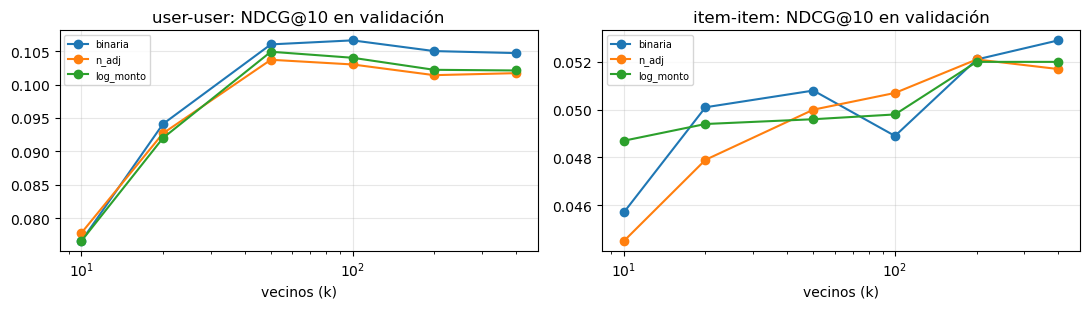

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for i, (nombre, g) in enumerate({"user-user": grilla_u, "item-item": grilla_i}.items()):
    for s in RANGO_SENAL:
        d = g[g.senal == s]
        ax[i].plot(d.k, d["ndcg@10"], "o-", label=s)
    ax[i].set_xscale("log"); ax[i].set_title(f"{nombre}: NDCG@10 en validación"); ax[i].set_xlabel("vecinos (k)"); ax[i].legend(fontsize=7)
mostrar_fig("grilla_vecindario")

- Item-item queda muy por debajo (máximo **0.053** con 400 vecinos)

- Con proveedores de grado bajo, la similitud entre columnas se apoya en muy pocas entidades y es ruidosa

---
### **3. Señal y vecinos elegidos**

In [8]:
mejor = {n: g.loc[g["ndcg@10"].idxmax()] for n, g in {"usuario": grilla_u, "item": grilla_i}.items()}
pd.DataFrame(mejor).T

,senal,k,precision@10,recall@10,ndcg@10,hit@10,cobertura,seg
usuario,binaria,100,0.0587,0.1101,0.1066,0.3875,0.392,2.4
item,binaria,400,0.0311,0.0586,0.0529,0.2135,0.787,3.4


- **User-user:** señal binaria y `k = 100` (NDCG 0.107 en validación)

- **Item-item:** señal binaria y `k = 400` (NDCG 0.053)

- `SENAL = binaria`: la intensidad no aporta, porque el 81% de los pares tiene una sola adjudicación

In [9]:
cfg["senal"] = SENAL
cfg["k_vec"] = K_VEC
guardar_config(cfg)

---
### **4. Evaluación en test**

- Se re-calculan las similitudes con 2023-2024 y se guardan los top-`N_CAND` de validación y de test para el híbrido

In [10]:
modelos = {"usuario": lambda c: puntaje_usuario(c["X"], K_VEC["usuario"]),
           "item": lambda c: puntaje_item(c["X"], K_VEC["item"], c["catalogo"])}
evaluacion = []
for p in PARTICIONES:
    c = ctx[(p, SENAL)]
    for nombre, f in modelos.items():
        t0 = time.time()
        recs = top_k(f(c), c["entidades"], c["vistos"], c["catalogo"])
        guardar_recs(recs, f"{nombre}_{p}")
        evaluacion.append({"particion": p, "modelo": nombre, **evaluar(recs, c["pos"], c["catalogo"].sum()), "seg": round(time.time() - t0, 1)})
evaluacion = pd.DataFrame(evaluacion)
evaluacion

,particion,modelo,precision@10,recall@10,ndcg@10,hit@10,cobertura,seg
0,val,usuario,0.0588,0.1107,0.1066,0.3885,0.3946,2.4
1,val,item,0.0315,0.0600,0.0541,0.2165,0.7896,3.4
2,test,usuario,0.0439,0.1037,0.0946,0.3305,0.2219,2.6
3,test,item,0.0265,0.0595,0.0525,0.2079,0.5984,6.3


- **User-user en test: NDCG@10 = 0.095**, recall@10 = 0.104; supera a la popularidad regional (0.081)

- Item-item: 0.053 en test

- Ambos calculan las recomendaciones de 2,112 entidades en ~3-7 s

---
### **5. Ejemplo: entidades vecinas**

Las vecinas de una entidad grande, para ver qué "parecido" captura el user-user

In [11]:
ent = pd.read_parquet(datos_dir / "entidades")
c = ctx[("test", SENAL)]
S = vecinas(c["X"], K_VEC["usuario"])
e0 = int(np.asarray(c["vistos"].sum(1)).ravel().argmax())
fila = S[e0].toarray().ravel()
top = np.argsort(-fila)[:8]
vecinas_ej = ent.loc[top, ["entidad_key", "nombre", "region"]].assign(similitud=fila[top].round(3))
print("entidad:", ent.nombre[e0], "|", ent.region[e0])
vecinas_ej

entidad: SEGURO SOCIAL DE SALUD | LIMA


,entidad_key,nombre,region,similitud
71,ENT:200551,INSTITUTO NACIONAL DE SALUD DEL NIÑO - SAN BORJA,LIMA,0.201
109,ENT:203086,HOSPITAL DE EMERGENCIAS VILLA EL SALVADOR,LIMA,0.197
31,ENT:200038,DIRECCIÓN DE SANIDAD DE LA PNP,LIMA,0.192
23,ENT:200363,CENTRO NACIONAL DE ABASTECIMIENTO DE RECURSOS ESTRATEGICOS EN SALUD,LIMA,0.182
93,ENT:10215,HOSPITAL NACIONAL DOS DE MAYO,LIMA,0.178
67,ENT:10198,INSTITUTO NACIONAL DE SALUD DEL NIÑO,LIMA,0.177
51,ENT:10194,INSTITUTO NACIONAL DE ENFERMEDADES NEOPLASICAS,LIMA,0.170
197,ENT:10424,GOBIERNO REGIONAL DE AREQUIPA-HOSPITAL REGIONAL HONORIO DELGADO,AREQUIPA,0.163


- Las vecinas de EsSalud son **hospitales e institutos de salud**, casi todos en Lima

- El user-user captura un "parecido" por **rubro y región**, sin haber visto el texto

#### a. Verificación

In [12]:
for p in PARTICIONES:
    c = ctx[(p, SENAL)]
    for m in modelos:
        r = leer_recs(f"{m}_{p}")
        assert set(r.entidad_idx) == set(c["pos"]) and c["catalogo"][r.proveedor_idx].all(), (m, p)
        assert c["vistos"][r.entidad_idx.to_numpy(), r.proveedor_idx.to_numpy()].sum() == 0, (m, p)
    print(f"{p}: recomendaciones dentro del catálogo y sin pares vistos | OK")

val: recomendaciones dentro del catálogo y sin pares vistos | OK
test: recomendaciones dentro del catálogo y sin pares vistos | OK


---
### **6. Escritura de resultados**

In [13]:
escritos = guardar_tablas({"grilla_usuario": grilla_u, "grilla_item": grilla_i, "evaluacion_vecindario": evaluacion,
                           "vecinas_ejemplo": vecinas_ej})

Escrito en 03_Recomend/temp/b_vecindario/: grilla_usuario, grilla_item, evaluacion_vecindario, vecinas_ejemplo


#### a. Verificación

In [14]:
verificar_salidas(escritos)

OK: 4 tablas (parquet + json) | 1 figuras: grilla_vecindario


---
### **7. Cerrar sesión**

In [15]:
spark.stop()